In [9]:
import torch
from FlowerDataset import FlowersDataset
from torch.utils.data import DataLoader, random_split, Subset
from Flowers_VAE import ResEncodingBlock
from scipy.io import loadmat
import importlib
import Flowers_VAE
from Flowers_VAE import VAE_Encoder
import torch.nn as nn
import numpy as np
import torch.optim as optim
from sklearn.model_selection import train_test_split
import time
import matplotlib.pyplot as plt
import triton
import torchvision

# Encoder test

## Prueba ResEncodingBlock

In [10]:
labels = loadmat("flower_labels.mat")
labels = labels["labels"][0]
dataset = FlowersDataset(labels)

test_inp, _ = dataset[0]

print(test_inp.shape)

res_block_test = ResEncodingBlock([3, 8, 16], [128, 128, 64], 7)

test_inp = test_inp.unsqueeze(0)
print(test_inp.shape)

out = res_block_test(test_inp)

print(out.shape)


torch.Size([3, 128, 128])
torch.Size([1, 3, 128, 128])
torch.Size([1, 16, 64, 64])


## Prueba encoder y chaining a un clasificador

In [11]:

importlib.reload(Flowers_VAE)

c = [[3, 32], [32, 64], [64, 128], [128, 256], [256, 512]]
r = [[128, 64], [64, 32], [32, 16], [16, 8], [8, 4]]
k = [3, 3, 3, 3, 3]
enc_test = VAE_Encoder(5, c, r, k, 1)

out, _, _ = enc_test(test_inp)

print(out.shape)


torch.Size([1, 512, 4, 4])


In [12]:

class FlowerClassifier(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        c = [[3, 32, 32], [32, 64, 64], [64, 128, 128], [128, 256, 256], [256, 512, 512] ]
        r = [[128, 128, 64], [64,64, 32], [32, 32, 16], [16,16, 8], [8,8, 4]]
        k = [3, 3, 3, 3, 3]
        
        self.encoder = VAE_Encoder(5, c, r, k, 1)
        
        self.avgPool = nn.AdaptiveAvgPool2d((1, 1))
        
        self.flat = nn.Flatten(start_dim=1)
        
        self.out_layer = nn.Linear(c[-1][-1], out_dim)

        self.dropout = nn.Dropout(0.4)
        
    
    def forward(self, x):
        y, _, _ = self.encoder(x)
        y = self.avgPool(y)
        
        y = self.flat(y)
        y = self.dropout(y)
        y = self.out_layer(y)
        return y

classifier = FlowerClassifier(102)

out = classifier(test_inp)

print(out.shape)

torch.Size([1, 102])


## Training loop and model test

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

labels = loadmat("flower_labels.mat")
labels = labels["labels"][0]
dataset = FlowersDataset(labels)


indices = list(range(len(dataset)))

# 70% train, 15% validation, 15% test
train_val_idx, test_idx = train_test_split(
    indices, test_size=0.15, stratify=labels, random_state=42
)

train_val_labels = [labels[i] for i in train_val_idx]

train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.15 / 0.85,
    stratify=train_val_labels, random_state=42
)

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)



print(device)



cuda


In [14]:
device = torch.device("cuda")
torch.set_float32_matmul_precision('high')
print(triton.__version__)
print(torch.__version__)
b_size = 128

train_loader = DataLoader(train_dataset, batch_size=b_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=b_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=b_size, shuffle=False)



classifier = FlowerClassifier(out_dim=102).to(device)


loss_crit = nn.CrossEntropyLoss()
optimizer = optim.AdamW(classifier.parameters(), lr = 1e-3)

train_losses = []
val_losses = []

min_loss = 9999.9
epochs = 30

for e in range(epochs):
    print(f"Starting epoch {e + 1}...")
    classifier.train()
    train_loss = 0.0
    start = time.perf_counter()
    
    for images, labels in train_loader:
        images = images.to(device, non_blocking= True)
        labels = labels.to(device, non_blocking= True)
        
        optimizer.zero_grad()
        
        out = classifier(images)
        loss = loss_crit(out, labels)
        
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
    
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    classifier.eval()
    val_loss = 0.0
    accuracy = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking= True)
            labels = labels.to(device, non_blocking= True)
            
            out = classifier(images)
            loss = loss_crit(out, labels)
            
            predictions = out.argmax(dim=1)
            
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            
            val_loss += loss.item() * images.size(0)
        
    accuracy = 100 * correct / total
    
    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)
    
    if val_loss < min_loss:
        min_loss = val_loss
        torch.save(classifier.state_dict(), "classifier.pth")
        
    elapsed = time.perf_counter() - start
    
    print(
        f"Epoch {e + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time taken: {elapsed:.2f} s | "
        f"Accuracy: {accuracy: .2f}%"
    )
    
    
    

3.6.0
2.11.0+cu128
Starting epoch 1...


KeyboardInterrupt: 

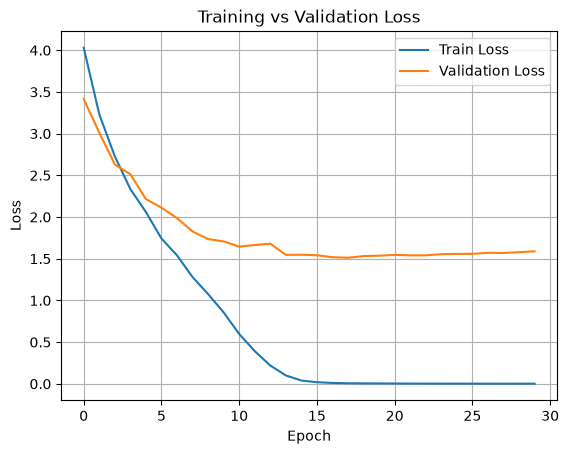

In [7]:
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Transfer Learing Classification test

In [40]:
train_loader = DataLoader(train_dataset, batch_size=b_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=b_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=b_size, shuffle=False)

classifier = torchvision.models.resnet50(weights = torchvision.models.ResNet50_Weights.DEFAULT)

In [41]:

classifier.fc = nn.Linear(classifier.fc.in_features, 102)
classifier = classifier.to(device)

for p in classifier.parameters():
    p.requires_grad = False

for p in classifier.fc.parameters():
    p.requires_grad = True
    
loss_crit = nn.CrossEntropyLoss()
optimizer = optim.AdamW(classifier.parameters(), lr = 1e-3)

In [42]:
b_size = 128


epochs = 30

train_losses = []
val_losses = []
val_accuracies = []

for e in range(epochs):
    print(f"Starting epoch {e + 1}...")
    classifier.train()
    train_loss = 0.0
    start = time.perf_counter()
    
    for images, labels in train_loader:
        images = images.to(device, non_blocking= True)
        labels = labels.to(device, non_blocking= True)
        
        optimizer.zero_grad()
        
        out = classifier(images)
        loss = loss_crit(out, labels)
        
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
    
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    classifier.eval()
    val_loss = 0.0
    accuracy = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking= True)
            labels = labels.to(device, non_blocking= True)
            
            out = classifier(images)
            loss = loss_crit(out, labels)
            
            predictions = out.argmax(dim=1)
            
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            
            val_loss += loss.item() * images.size(0)
        
    accuracy = 100 * correct / total
    
    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)
    
    if val_loss < min_loss:
        min_loss = val_loss
        torch.save(classifier.state_dict(), "classifier.pth")
        
    elapsed = time.perf_counter() - start
    
    print(
        f"Epoch {e + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time taken: {elapsed:.2f} s | "
        f"Accuracy: {accuracy: .2f}%"
    )
    
    
    

Starting epoch 1...
Epoch 1/30 | Train Loss: 3.6226 | Val Loss: 2.7463 | Time taken: 29.70 s | Accuracy:  58.75%
Starting epoch 2...
Epoch 2/30 | Train Loss: 2.0393 | Val Loss: 1.8483 | Time taken: 27.46 s | Accuracy:  74.86%
Starting epoch 3...
Epoch 3/30 | Train Loss: 1.2983 | Val Loss: 1.4716 | Time taken: 27.73 s | Accuracy:  79.09%
Starting epoch 4...
Epoch 4/30 | Train Loss: 0.8977 | Val Loss: 1.2651 | Time taken: 27.37 s | Accuracy:  82.67%
Starting epoch 5...
Epoch 5/30 | Train Loss: 0.6721 | Val Loss: 1.0850 | Time taken: 28.16 s | Accuracy:  82.99%
Starting epoch 6...
Epoch 6/30 | Train Loss: 0.5246 | Val Loss: 0.9700 | Time taken: 26.67 s | Accuracy:  83.40%
Starting epoch 7...
Epoch 7/30 | Train Loss: 0.4172 | Val Loss: 0.9221 | Time taken: 28.22 s | Accuracy:  84.46%
Starting epoch 8...
Epoch 8/30 | Train Loss: 0.3440 | Val Loss: 0.8440 | Time taken: 26.72 s | Accuracy:  83.81%
Starting epoch 9...
Epoch 9/30 | Train Loss: 0.3027 | Val Loss: 0.8375 | Time taken: 27.86 s | A

KeyboardInterrupt: 